Dataset shape: (342, 8)
CART Accuracy: 0.9420289855072463
Logistic Regression Accuracy: 0.9855072463768116


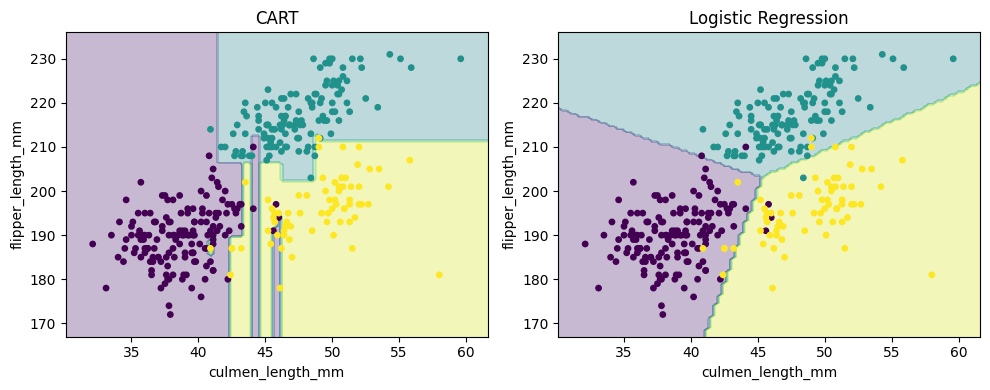


CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.88      1.00      0.94        30
   Chinstrap       1.00      0.79      0.88        14
      Gentoo       1.00      0.96      0.98        25

    accuracy                           0.94        69
   macro avg       0.96      0.92      0.93        69
weighted avg       0.95      0.94      0.94        69



In [4]:

# Task 9: CART Decision Tree vs. Linear Classification Boundary

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# 1. Load Dataset and Select Features
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(url)

# Fix column name differences
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'bill_length_mm': 'culmen_length_mm',
    'Culmen Length (mm)': 'culmen_length_mm',
    'Flipper Length (mm)': 'flipper_length_mm',
    'Species': 'species'
})

df = df.dropna(subset=[
    'culmen_length_mm', 'flipper_length_mm', 'species'
])

X = df[['culmen_length_mm', 'flipper_length_mm']]
y = df['species']

print("Dataset shape:", df.shape)

# 2. Train CART Decision Tree and Logistic Regression
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cart_model = DecisionTreeClassifier(
    criterion='gini', random_state=42
)
cart_model.fit(X_train, y_train)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

print("CART Accuracy:", cart_model.score(X_test, y_test))
print("Logistic Regression Accuracy:", log_model.score(X_test, y_test))

# 3. Plot Decision Boundaries
xx, yy = np.meshgrid(
    np.linspace(X.iloc[:, 0].min()-2, X.iloc[:, 0].max()+2, 100),
    np.linspace(X.iloc[:, 1].min()-5, X.iloc[:, 1].max()+5, 100)
)
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, model, title in zip(
    axes, [cart_model, log_model], ['CART', 'Logistic Regression']
):
    Z = pd.Categorical(model.predict(grid), categories=y.unique()).codes.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X.iloc[:, 0], X.iloc[:, 1],
               c=pd.Categorical(y, categories=y.unique()).codes,
               cmap='viridis', s=15)
    ax.set_title(title)
    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])

plt.tight_layout()
plt.show()

# 4. Classification Report for CART
y_pred = cart_model.predict(X_test)
print("\nCART Classification Report:")
print(classification_report(y_test, y_pred))
